In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path

DATA_DIR = Path("/content/drive/Othercomputers/Mi portátil/Documents/MNA/Operaciones de aprendizaje automático/datamibici2025")

files_2025 = sorted(DATA_DIR.glob("datos_abiertos_2025_*.csv"))

print("Archivos encontrados:", len(files_2025))

for f in files_2025:
    print(f.name)

Archivos encontrados: 12
datos_abiertos_2025_01.csv
datos_abiertos_2025_02.csv
datos_abiertos_2025_03.csv
datos_abiertos_2025_04.csv
datos_abiertos_2025_05.csv
datos_abiertos_2025_06.csv
datos_abiertos_2025_07.csv
datos_abiertos_2025_08.csv
datos_abiertos_2025_09.csv
datos_abiertos_2025_10.csv
datos_abiertos_2025_11.csv
datos_abiertos_2025_12.csv


In [ ]:
import pandas as pd
import numpy as np
import gc

def detectar_encoding(path):
    for encoding in ["utf-8-sig", "utf-8", "cp1252", "latin1"]:
        try:
            pd.read_csv(path, encoding=encoding, nrows=5)
            return encoding
        except UnicodeDecodeError:
            continue
    return None

revision = []

for archivo in files_2025:
    encoding = detectar_encoding(archivo)
    df = pd.read_csv(archivo, encoding=encoding, nrows=5)

    revision.append({
        "archivo": archivo.name,
        "encoding": encoding,
        "columnas": len(df.columns),
        "nombres": list(df.columns)
    })

revision_df = pd.DataFrame(revision)

display(revision_df[["archivo", "encoding", "columnas"]])

print("\nArchivos:", len(revision_df))
print("\nEncodings:")
print(revision_df["encoding"].value_counts())

,archivo,encoding,columnas
0,datos_abiertos_2025_01.csv,cp1252,8
1,datos_abiertos_2025_02.csv,cp1252,8
2,datos_abiertos_2025_03.csv,utf-8-sig,8
3,datos_abiertos_2025_04.csv,utf-8-sig,8
4,datos_abiertos_2025_05.csv,utf-8-sig,8
5,datos_abiertos_2025_06.csv,utf-8-sig,8
6,datos_abiertos_2025_07.csv,cp1252,8
7,datos_abiertos_2025_08.csv,utf-8-sig,8
8,datos_abiertos_2025_09.csv,utf-8-sig,8
9,datos_abiertos_2025_10.csv,utf-8-sig,8



Archivos: 12

Encodings:
encoding
utf-8-sig    9
cp1252       3
Name: count, dtype: int64


In [ ]:
COLUMNAS_P3 = [
    "Viaje_Id",
    "Inicio_del_viaje",
    "Fin_del_viaje",
    "Origen_Id",
    "Destino_Id"
]

FORMATOS_FECHA = {
    "ISO_segundos": "%Y-%m-%d %H:%M:%S",
    "ISO_minutos": "%Y-%m-%d %H:%M",
    "DMY_segundos": "%d/%m/%Y %H:%M:%S",
    "DMY_minutos": "%d/%m/%Y %H:%M"
}

def detectar_formato_fecha(serie):
    muestra = serie.dropna().head(2000)

    resultados = {}

    for nombre, formato in FORMATOS_FECHA.items():
        parsed = pd.to_datetime(
            muestra,
            format=formato,
            errors="coerce"
        )
        resultados[nombre] = parsed.notna().mean()

    mejor = max(resultados, key=resultados.get)

    if resultados[mejor] < 0.99:
        raise ValueError("Formato de fecha no reconocido")

    return FORMATOS_FECHA[mejor], mejor

def cargar_mes_p3(path):
    encoding = detectar_encoding(path)

    df = pd.read_csv(
        path,
        encoding=encoding,
        usecols=COLUMNAS_P3
    )

    formato_inicio, nombre_inicio = detectar_formato_fecha(
        df["Inicio_del_viaje"]
    )

    formato_fin, nombre_fin = detectar_formato_fecha(
        df["Fin_del_viaje"]
    )

    df["Inicio_del_viaje"] = pd.to_datetime(
        df["Inicio_del_viaje"],
        format=formato_inicio,
        errors="coerce"
    )

    df["Fin_del_viaje"] = pd.to_datetime(
        df["Fin_del_viaje"],
        format=formato_fin,
        errors="coerce"
    )

    return df, nombre_inicio

revision_fechas = []

for archivo in files_2025:
    df, formato = cargar_mes_p3(archivo)

    revision_fechas.append({
        "archivo": archivo.name,
        "formato": formato,
        "filas": len(df),
        "nulos_inicio": df["Inicio_del_viaje"].isna().sum(),
        "nulos_fin": df["Fin_del_viaje"].isna().sum()
    })

    del df
    gc.collect()

revision_fechas_df = pd.DataFrame(revision_fechas)

display(revision_fechas_df)

print("\nFormatos:")
print(revision_fechas_df["formato"].value_counts())

print("\nFilas totales:", f"{revision_fechas_df['filas'].sum():,}")
print("Nulos inicio:", revision_fechas_df["nulos_inicio"].sum())
print("Nulos fin:", revision_fechas_df["nulos_fin"].sum())

,archivo,formato,filas,nulos_inicio,nulos_fin
0,datos_abiertos_2025_01.csv,ISO_segundos,380184,0,0
1,datos_abiertos_2025_02.csv,ISO_segundos,372529,0,0
2,datos_abiertos_2025_03.csv,ISO_segundos,405110,0,0
3,datos_abiertos_2025_04.csv,ISO_segundos,366193,0,0
4,datos_abiertos_2025_05.csv,ISO_segundos,395891,0,0
5,datos_abiertos_2025_06.csv,ISO_segundos,356611,0,0
6,datos_abiertos_2025_07.csv,ISO_segundos,368186,0,0
7,datos_abiertos_2025_08.csv,ISO_segundos,374727,0,0
8,datos_abiertos_2025_09.csv,ISO_segundos,376789,0,0
9,datos_abiertos_2025_10.csv,ISO_segundos,420064,0,0



Formatos:
formato
ISO_segundos    12
Name: count, dtype: int64

Filas totales: 4,532,032
Nulos inicio: 0
Nulos fin: 0


In [ ]:
frames = []

for archivo in files_2025:
    df, _ = cargar_mes_p3(archivo)

    duracion = (
        df["Fin_del_viaje"] - df["Inicio_del_viaje"]
    ).dt.total_seconds()

    df = df[
        (duracion >= 60) &
        (duracion <= 86400)
    ].copy()

    frames.append(df)

df_2025 = pd.concat(frames, ignore_index=True)

TRAIN_END = pd.Timestamp("2025-10-19 23:59:59")
TEST_START = pd.Timestamp("2025-10-20 00:00:00")

train_df = df_2025[
    df_2025["Inicio_del_viaje"] <= TRAIN_END
].copy()

test_df = df_2025[
    df_2025["Inicio_del_viaje"] >= TEST_START
].copy()

print("Total limpio:", f"{len(df_2025):,}")
print("Train:", f"{len(train_df):,}")
print("Test:", f"{len(test_df):,}")

print("\nTrain %:", f"{len(train_df) / len(df_2025):.2%}")
print("Test %:", f"{len(test_df) / len(df_2025):.2%}")

print("\nTrain:")
print(train_df["Inicio_del_viaje"].min())
print(train_df["Inicio_del_viaje"].max())

print("\nTest:")
print(test_df["Inicio_del_viaje"].min())
print(test_df["Inicio_del_viaje"].max())

del frames
gc.collect()


Total limpio: 4,414,800
Train: 3,552,805
Test: 861,995

Train %: 80.47%
Test %: 19.53%

Train:
2025-01-01 00:00:44
2025-10-19 23:59:32

Test:
2025-10-20 00:00:49
2025-12-31 23:58:23


0

In [ ]:
duplicados_id = df_2025["Viaje_Id"].duplicated().sum()
duplicados_exactos = df_2025.duplicated().sum()

nulos_origen = df_2025["Origen_Id"].isna().sum()
nulos_destino = df_2025["Destino_Id"].isna().sum()

cruce_split = (
    (df_2025["Inicio_del_viaje"] <= TRAIN_END) &
    (df_2025["Fin_del_viaje"] >= TEST_START)
).sum()

fin_fuera_2025 = (
    df_2025["Fin_del_viaje"] >= pd.Timestamp("2026-01-01")
).sum()

print("Viaje_Id duplicados:", f"{duplicados_id:,}")
print("Filas exactamente duplicadas:", f"{duplicados_exactos:,}")
print("Origen nulo:", f"{nulos_origen:,}")
print("Destino nulo:", f"{nulos_destino:,}")
print("Cruzan frontera train/test:", f"{cruce_split:,}")
print("Terminan en 2026:", f"{fin_fuera_2025:,}")

Viaje_Id duplicados: 0
Filas exactamente duplicadas: 0
Origen nulo: 0
Destino nulo: 0
Cruzan frontera train/test: 17
Terminan en 2026: 7


In [ ]:
train_df = train_df[
    train_df["Fin_del_viaje"] < TEST_START
].copy()

TEST_END = pd.Timestamp("2026-01-01 00:00:00")

test_df = test_df[
    test_df["Fin_del_viaje"] < TEST_END
].copy()

print("Train final:", f"{len(train_df):,}")
print("Test final:", f"{len(test_df):,}")

print(
    "Train cruza a test:",
    (train_df["Fin_del_viaje"] >= TEST_START).sum()
)

print(
    "Test cruza a 2026:",
    (test_df["Fin_del_viaje"] >= TEST_END).sum()
)

Train final: 3,552,788
Test final: 861,988
Train cruza a test: 0
Test cruza a 2026: 0


In [ ]:
salidas = train_df[
    ["Inicio_del_viaje", "Origen_Id"]
].rename(
    columns={
        "Inicio_del_viaje": "fecha",
        "Origen_Id": "estacion"
    }
)

llegadas = train_df[
    ["Fin_del_viaje", "Destino_Id"]
].rename(
    columns={
        "Fin_del_viaje": "fecha",
        "Destino_Id": "estacion"
    }
)

eventos_train = pd.concat(
    [salidas, llegadas],
    ignore_index=True
)

eventos_train["dia"] = eventos_train["fecha"].dt.normalize()
eventos_train["mes"] = eventos_train["fecha"].dt.to_period("M")

cobertura_train = (
    eventos_train
    .groupby("estacion")
    .agg(
        primera_actividad=("fecha", "min"),
        ultima_actividad=("fecha", "max"),
        dias_activos=("dia", "nunique"),
        meses_activos=("mes", "nunique"),
        movimientos=("fecha", "size")
    )
    .reset_index()
)

print("Estaciones TRAIN:", len(cobertura_train))

print("\nMeses activos:")
print(
    cobertura_train["meses_activos"]
    .value_counts()
    .sort_index()
)

print("\nCobertura mínima:")
print(cobertura_train["meses_activos"].min(), "meses")
print(cobertura_train["dias_activos"].min(), "días")

print("\nCobertura máxima:")
print(cobertura_train["meses_activos"].max(), "meses")
print(cobertura_train["dias_activos"].max(), "días")

print("\nEstaciones activas en los últimos 30 días de TRAIN:")
print(
    (
        cobertura_train["ultima_actividad"]
        >= pd.Timestamp("2025-09-20")
    ).sum()
)

Estaciones TRAIN: 370

Meses activos:
meses_activos
1       2
5       1
6       1
10    366
Name: count, dtype: int64

Cobertura mínima:
1 meses
11 días

Cobertura máxima:
10 meses
292 días

Estaciones activas en los últimos 30 días de TRAIN:
368


In [ ]:
especiales = cobertura_train[
    (cobertura_train["meses_activos"] < 10) |
    (cobertura_train["ultima_actividad"] < pd.Timestamp("2025-09-20"))
].copy()

especiales = especiales.sort_values(
    ["meses_activos", "primera_actividad"]
)

display(especiales)


,estacion,primera_actividad,ultima_actividad,dias_activos,meses_activos,movimientos
160,180,2025-01-01 07:32:33,2025-01-28 16:54:54,28,1,2252
369,401,2025-10-09 18:07:56,2025-10-19 15:18:52,11,1,74
368,400,2025-06-09 18:23:16,2025-10-19 21:33:42,133,5,8395
219,240,2025-01-01 15:11:21,2025-06-06 09:52:00,156,6,951


In [ ]:
fin_train = train_df["Inicio_del_viaje"].max()

cobertura_train["dias_sin_actividad"] = (
    fin_train - cobertura_train["ultima_actividad"]
).dt.days

cobertura_train["eligible_p3"] = (
    (cobertura_train["dias_sin_actividad"] < 60) &
    (cobertura_train["dias_activos"] >= 30)
)

cobertura_train["motivo_omision"] = np.select(
    [
        cobertura_train["dias_sin_actividad"] >= 60,
        cobertura_train["dias_activos"] < 30
    ],
    [
        "inactividad_60_dias",
        "historial_insuficiente"
    ],
    default="elegible"
)

print(cobertura_train["motivo_omision"].value_counts())

display(
    cobertura_train.loc[
        ~cobertura_train["eligible_p3"],
        [
            "estacion",
            "primera_actividad",
            "ultima_actividad",
            "dias_activos",
            "movimientos",
            "dias_sin_actividad",
            "motivo_omision"
        ]
    ]
)

motivo_omision
elegible                  367
inactividad_60_dias         2
historial_insuficiente      1
Name: count, dtype: int64


,estacion,primera_actividad,ultima_actividad,dias_activos,movimientos,dias_sin_actividad,motivo_omision
160,180,2025-01-01 07:32:33,2025-01-28 16:54:54,28,2252,264,inactividad_60_dias
219,240,2025-01-01 15:11:21,2025-06-06 09:52:00,156,951,135,inactividad_60_dias
369,401,2025-10-09 18:07:56,2025-10-19 15:18:52,11,74,0,historial_insuficiente


In [ ]:
cobertura_train["dias_historial"] = (
    cobertura_train["ultima_actividad"] -
    cobertura_train["primera_actividad"]
).dt.days + 1

cobertura_train["eligible_p3"] = (
    (cobertura_train["dias_sin_actividad"] < 60) &
    (cobertura_train["dias_historial"] >= 30)
)

cobertura_train["motivo_omision"] = np.select(
    [
        cobertura_train["dias_sin_actividad"] >= 60,
        cobertura_train["dias_historial"] < 30
    ],
    [
        "inactividad_60_dias",
        "historial_insuficiente"
    ],
    default="elegible"
)

print(cobertura_train["motivo_omision"].value_counts())

display(
    cobertura_train.loc[
        ~cobertura_train["eligible_p3"],
        [
            "estacion",
            "primera_actividad",
            "ultima_actividad",
            "dias_historial",
            "dias_sin_actividad",
            "movimientos",
            "motivo_omision"
        ]
    ]
)

motivo_omision
elegible                  367
inactividad_60_dias         2
historial_insuficiente      1
Name: count, dtype: int64


,estacion,primera_actividad,ultima_actividad,dias_historial,dias_sin_actividad,movimientos,motivo_omision
160,180,2025-01-01 07:32:33,2025-01-28 16:54:54,28,264,2252,inactividad_60_dias
219,240,2025-01-01 15:11:21,2025-06-06 09:52:00,156,135,951,inactividad_60_dias
369,401,2025-10-09 18:07:56,2025-10-19 15:18:52,10,0,74,historial_insuficiente


In [ ]:
estaciones_p3 = cobertura_train.loc[
    cobertura_train["eligible_p3"],
    ["estacion", "primera_actividad"]
].copy()

estaciones_p3["dias_exposicion"] = (
    fin_train.normalize() -
    estaciones_p3["primera_actividad"].dt.normalize()
).dt.days + 1

ids_p3 = set(estaciones_p3["estacion"])

salidas = train_df.loc[
    train_df["Origen_Id"].isin(ids_p3),
    ["Origen_Id", "Inicio_del_viaje"]
].copy()

salidas.columns = ["estacion", "fecha"]

llegadas = train_df.loc[
    train_df["Destino_Id"].isin(ids_p3),
    ["Destino_Id", "Fin_del_viaje"]
].copy()

llegadas.columns = ["estacion", "fecha"]

def agregar_bloque(df):
    hora = df["fecha"].dt.hour

    df["bloque"] = np.select(
        [
            (hora >= 5) & (hora <= 10),
            (hora >= 11) & (hora <= 15),
            (hora >= 16) & (hora <= 20)
        ],
        [
            "manana",
            "mediodia",
            "tarde"
        ],
        default="noche"
    )

    df["fin_semana"] = df["fecha"].dt.dayofweek >= 5

    return df

salidas = agregar_bloque(salidas)
llegadas = agregar_bloque(llegadas)

base = estaciones_p3.set_index("estacion")

base["salidas"] = salidas.groupby("estacion").size()
base["llegadas"] = llegadas.groupby("estacion").size()

base["salidas_fin_semana"] = (
    salidas.loc[salidas["fin_semana"]]
    .groupby("estacion")
    .size()
)

base["llegadas_fin_semana"] = (
    llegadas.loc[llegadas["fin_semana"]]
    .groupby("estacion")
    .size()
)

bloques_salida = (
    salidas.groupby(["estacion", "bloque"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["manana", "mediodia", "tarde", "noche"], fill_value=0)
)

bloques_llegada = (
    llegadas.groupby(["estacion", "bloque"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["manana", "mediodia", "tarde", "noche"], fill_value=0)
)

base = base.join(
    bloques_salida.add_prefix("salida_")
)

base = base.join(
    bloques_llegada.add_prefix("llegada_")
)

base = base.fillna(0)

features_train = pd.DataFrame(index=base.index)

features_train["salidas_dia"] = (
    base["salidas"] / base["dias_exposicion"]
)

features_train["llegadas_dia"] = (
    base["llegadas"] / base["dias_exposicion"]
)

features_train["balance_relativo"] = (
    (base["llegadas"] - base["salidas"]) /
    (base["llegadas"] + base["salidas"])
)

features_train["share_fin_semana"] = (
    (base["salidas_fin_semana"] + base["llegadas_fin_semana"]) /
    (base["salidas"] + base["llegadas"])
)

for bloque in ["manana", "mediodia", "tarde", "noche"]:
    features_train[f"salida_{bloque}_share"] = (
        base[f"salida_{bloque}"] / base["salidas"]
    )

    features_train[f"llegada_{bloque}_share"] = (
        base[f"llegada_{bloque}"] / base["llegadas"]
    )

features_train = features_train.fillna(0)

print("Estaciones:", len(features_train))
print("Features:", features_train.shape[1])

display(features_train.head())

Estaciones: 367
Features: 12


,salidas_dia,llegadas_dia,balance_relativo,share_fin_semana,salida_manana_share,llegada_manana_share,salida_mediodia_share,llegada_mediodia_share,salida_tarde_share,llegada_tarde_share,salida_noche_share,llegada_noche_share
estacion,,,,,,,,,,,,
2,50.643836,54.123288,0.033211,0.180701,0.353327,0.267654,0.270895,0.266135,0.321680,0.412744,0.054098,0.053467
3,50.633562,45.178082,-0.056940,0.192194,0.258032,0.339069,0.261346,0.260992,0.384579,0.312841,0.096043,0.087098
4,63.767123,61.917808,-0.014714,0.223324,0.212567,0.342533,0.253061,0.280918,0.419066,0.303097,0.115306,0.073451
5,51.092466,52.613014,0.014662,0.185457,0.415376,0.293953,0.297473,0.274100,0.243917,0.339908,0.043233,0.092039
6,24.424658,32.184932,0.137084,0.214217,0.364414,0.233028,0.281268,0.288359,0.274257,0.375293,0.080062,0.103320


In [ ]:
auditoria = pd.DataFrame({
    "min": features_train.min(),
    "media": features_train.mean(),
    "std": features_train.std(),
    "max": features_train.max(),
    "skew": features_train.skew(),
    "nulos": features_train.isna().sum(),
    "inf": np.isinf(features_train).sum(),
    "unicos": features_train.nunique()
})

display(auditoria)

salida_cols = [
    "salida_manana_share",
    "salida_mediodia_share",
    "salida_tarde_share",
    "salida_noche_share"
]

llegada_cols = [
    "llegada_manana_share",
    "llegada_mediodia_share",
    "llegada_tarde_share",
    "llegada_noche_share"
]

suma_salidas = features_train[salida_cols].sum(axis=1)
suma_llegadas = features_train[llegada_cols].sum(axis=1)

print("Nulos totales:", features_train.isna().sum().sum())
print("Infinitos totales:", np.isinf(features_train).sum().sum())
print("Features constantes:", (features_train.nunique() <= 1).sum())

print("\nSuma shares salida:")
print(suma_salidas.min(), suma_salidas.max())

print("\nSuma shares llegada:")
print(suma_llegadas.min(), suma_llegadas.max())

print("\nBalance fuera de [-1, 1]:",
      ((features_train["balance_relativo"] < -1) |
       (features_train["balance_relativo"] > 1)).sum())

,min,media,std,max,skew,nulos,inf,unicos
salidas_dia,3.496575,33.180492,30.526828,234.804795,2.702632,0,0,366
llegadas_dia,2.695205,33.188576,33.047585,311.109589,3.440106,0,0,362
balance_relativo,-0.348956,-0.021948,0.124905,0.532206,0.571054,0,0,367
share_fin_semana,0.065728,0.207833,0.052611,0.522821,1.781603,0,0,367
salida_manana_share,0.051948,0.295835,0.096106,0.593987,0.206961,0,0,367
llegada_manana_share,0.061580,0.269950,0.096008,0.574802,0.304008,0,0,367
salida_mediodia_share,0.161820,0.282188,0.052129,0.495457,0.659479,0,0,367
llegada_mediodia_share,0.171779,0.283126,0.049247,0.442953,0.480260,0,0,367
salida_tarde_share,0.124839,0.346693,0.074298,0.635338,0.346866,0,0,367
llegada_tarde_share,0.175534,0.352456,0.077232,0.603265,0.199049,0,0,367


Nulos totales: 0
Infinitos totales: 0
Features constantes: 0

Suma shares salida:
0.9999999999999999 1.0000000000000002

Suma shares llegada:
0.9999999999999999 1.0000000000000002

Balance fuera de [-1, 1]: 0


In [ ]:
features_modelo = features_train.copy()

features_modelo["salidas_dia"] = np.log1p(
    features_modelo["salidas_dia"]
)

features_modelo["llegadas_dia"] = np.log1p(
    features_modelo["llegadas_dia"]
)

print("Skew original:")
print(
    features_train[
        ["salidas_dia", "llegadas_dia"]
    ].skew()
)

print("\nSkew después de log1p:")
print(
    features_modelo[
        ["salidas_dia", "llegadas_dia"]
    ].skew()
)

display(
    features_modelo[
        ["salidas_dia", "llegadas_dia"]
    ].describe()
)

Skew original:
salidas_dia     2.702632
llegadas_dia    3.440106
dtype: float64

Skew después de log1p:
salidas_dia     0.074345
llegadas_dia   -0.074599
dtype: float64


,salidas_dia,llegadas_dia
count,367.000000,367.000000
mean,3.219268,3.181932
std,0.793542,0.852776
min,1.503316,1.307036
25%,2.608628,2.601546
50%,3.218739,3.258097
75%,3.808449,3.764413
max,5.463004,5.743354


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(features_modelo),
    index=features_modelo.index,
    columns=features_modelo.columns
)

print("Shape:", X_train_scaled.shape)
print("Media máxima absoluta:", X_train_scaled.mean().abs().max())
print("Std mínima:", X_train_scaled.std(ddof=0).min())
print("Std máxima:", X_train_scaled.std(ddof=0).max())

display(X_train_scaled.head())


Shape: (367, 12)
Media máxima absoluta: 9.390006181025848e-16
Std mínima: 0.9999999999999996
Std máxima: 1.0000000000000004


,salidas_dia,llegadas_dia,balance_relativo,share_fin_semana,salida_manana_share,llegada_manana_share,salida_mediodia_share,llegada_mediodia_share,salida_tarde_share,llegada_tarde_share,salida_noche_share,llegada_noche_share
estacion,,,,,,,,,,,,
2,0.915002,0.971850,0.442216,-0.516414,0.599031,-0.023952,-0.216935,-0.345480,-0.337123,0.781669,-0.677486,-1.061118
3,0.914750,0.763930,-0.280525,-0.297666,-0.393885,0.720910,-0.400372,-0.450068,0.510619,-0.513627,0.663864,-0.190736
4,1.200728,1.127152,0.057999,0.294861,-0.867598,0.757040,-0.559516,-0.044892,0.975421,-0.639961,1.279860,-0.543925
5,0.925916,0.939229,0.293508,-0.425893,1.245546,0.250349,0.293606,-0.183526,-1.385189,-0.162694,-1.024914,-0.062859
6,0.020760,0.375950,1.274966,0.121510,0.714549,-0.385096,-0.017691,0.106410,-0.976277,0.296095,0.152796,0.229088


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

resultados_k = []

for k in range(2, 11):
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = modelo.fit_predict(X_train_scaled)

    conteos = pd.Series(labels).value_counts()

    resultados_k.append({
        "k": k,
        "silhouette": silhouette_score(X_train_scaled, labels),
        "davies_bouldin": davies_bouldin_score(X_train_scaled, labels),
        "calinski_harabasz": calinski_harabasz_score(X_train_scaled, labels),
        "inercia": modelo.inertia_,
        "cluster_min": conteos.min(),
        "cluster_max": conteos.max(),
        "cluster_max_pct": conteos.max() / len(labels)
    })

resultados_k = pd.DataFrame(resultados_k)

display(
    resultados_k.style.format({
        "silhouette": "{:.4f}",
        "davies_bouldin": "{:.4f}",
        "calinski_harabasz": "{:.2f}",
        "inercia": "{:.2f}",
        "cluster_max_pct": "{:.2%}"
    })
)

,k,silhouette,davies_bouldin,calinski_harabasz,inercia,cluster_min,cluster_max,cluster_max_pct
0,2,0.1977,1.7715,100.83,3450.76,161,206,56.13%
1,3,0.1773,1.8178,85.94,2991.41,96,148,40.33%
2,4,0.1864,1.5841,80.72,2641.68,39,127,34.60%
3,5,0.1508,1.7201,71.69,2457.35,37,99,26.98%
4,6,0.1474,1.7807,64.36,2328.33,34,100,27.25%
5,7,0.1415,1.7428,59.42,2212.62,35,84,22.89%
6,8,0.1323,1.7931,55.73,2110.60,23,62,16.89%
7,9,0.1466,1.6789,53.46,2006.68,13,69,18.80%
8,10,0.1430,1.6386,50.40,1939.58,17,64,17.44%


In [ ]:
comparacion_perfiles = {}

for k in [2, 4]:
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = modelo.fit_predict(X_train_scaled)

    perfiles = features_train.copy()
    perfiles["cluster"] = labels

    resumen = perfiles.groupby("cluster").mean()
    resumen["estaciones"] = perfiles["cluster"].value_counts().sort_index()

    comparacion_perfiles[k] = resumen

    print(f"\nK = {k}")
    display(resumen.round(3))


K = 2


,salidas_dia,llegadas_dia,balance_relativo,share_fin_semana,salida_manana_share,llegada_manana_share,salida_mediodia_share,llegada_mediodia_share,salida_tarde_share,llegada_tarde_share,salida_noche_share,llegada_noche_share,estaciones
cluster,,,,,,,,,,,,,
0,39.826,38.082,-0.057,0.203,0.232,0.324,0.296,0.294,0.387,0.308,0.084,0.075,206
1,24.678,26.927,0.023,0.214,0.378,0.201,0.264,0.270,0.295,0.410,0.064,0.119,161



K = 4


,salidas_dia,llegadas_dia,balance_relativo,share_fin_semana,salida_manana_share,llegada_manana_share,salida_mediodia_share,llegada_mediodia_share,salida_tarde_share,llegada_tarde_share,salida_noche_share,llegada_noche_share,estaciones
cluster,,,,,,,,,,,,,
0,20.399,17.351,-0.088,0.291,0.261,0.283,0.341,0.366,0.329,0.283,0.069,0.068,39
1,27.437,24.053,-0.092,0.181,0.217,0.369,0.273,0.264,0.424,0.297,0.086,0.070,108
2,13.027,14.435,0.022,0.212,0.405,0.181,0.251,0.258,0.283,0.430,0.061,0.132,93
3,56.748,59.554,0.026,0.202,0.294,0.247,0.295,0.293,0.333,0.364,0.078,0.096,127


In [ ]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

def construir_features_p3(df, fin_periodo, max_inactivity_days=60, min_history_days=30):
    salidas_ev = df[["Inicio_del_viaje", "Origen_Id"]].rename(
        columns={"Inicio_del_viaje": "fecha", "Origen_Id": "estacion"}
    )

    llegadas_ev = df[["Fin_del_viaje", "Destino_Id"]].rename(
        columns={"Fin_del_viaje": "fecha", "Destino_Id": "estacion"}
    )

    eventos = pd.concat([salidas_ev, llegadas_ev], ignore_index=True)
    eventos["dia"] = eventos["fecha"].dt.normalize()

    cobertura = (
        eventos.groupby("estacion")
        .agg(
            primera_actividad=("fecha", "min"),
            ultima_actividad=("fecha", "max"),
            dias_activos=("dia", "nunique"),
            movimientos=("fecha", "size")
        )
        .reset_index()
    )

    cobertura["dias_historial"] = (
        cobertura["ultima_actividad"] -
        cobertura["primera_actividad"]
    ).dt.days + 1

    cobertura["dias_sin_actividad"] = (
        fin_periodo -
        cobertura["ultima_actividad"]
    ).dt.days

    cobertura["eligible_p3"] = (
        (cobertura["dias_sin_actividad"] < max_inactivity_days) &
        (cobertura["dias_historial"] >= min_history_days)
    )

    elegibles = cobertura.loc[
        cobertura["eligible_p3"],
        ["estacion", "primera_actividad"]
    ].copy()

    elegibles["dias_exposicion"] = (
        fin_periodo.normalize() -
        elegibles["primera_actividad"].dt.normalize()
    ).dt.days + 1

    ids = set(elegibles["estacion"])

    salidas = df.loc[
        df["Origen_Id"].isin(ids),
        ["Origen_Id", "Inicio_del_viaje"]
    ].copy()

    llegadas = df.loc[
        df["Destino_Id"].isin(ids),
        ["Destino_Id", "Fin_del_viaje"]
    ].copy()

    salidas.columns = ["estacion", "fecha"]
    llegadas.columns = ["estacion", "fecha"]

    for datos in [salidas, llegadas]:
        hora = datos["fecha"].dt.hour

        datos["bloque"] = np.select(
            [
                (hora >= 5) & (hora <= 10),
                (hora >= 11) & (hora <= 15),
                (hora >= 16) & (hora <= 20)
            ],
            ["manana", "mediodia", "tarde"],
            default="noche"
        )

        datos["fin_semana"] = datos["fecha"].dt.dayofweek >= 5

    base = elegibles.set_index("estacion")

    base["salidas"] = salidas.groupby("estacion").size()
    base["llegadas"] = llegadas.groupby("estacion").size()

    base["salidas_fin_semana"] = (
        salidas.loc[salidas["fin_semana"]]
        .groupby("estacion")
        .size()
    )

    base["llegadas_fin_semana"] = (
        llegadas.loc[llegadas["fin_semana"]]
        .groupby("estacion")
        .size()
    )

    bloques_salida = (
        salidas.groupby(["estacion", "bloque"])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=["manana", "mediodia", "tarde", "noche"], fill_value=0)
    )

    bloques_llegada = (
        llegadas.groupby(["estacion", "bloque"])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=["manana", "mediodia", "tarde", "noche"], fill_value=0)
    )

    base = base.join(bloques_salida.add_prefix("salida_"))
    base = base.join(bloques_llegada.add_prefix("llegada_"))
    base = base.fillna(0)

    features = pd.DataFrame(index=base.index)

    features["salidas_dia"] = base["salidas"] / base["dias_exposicion"]
    features["llegadas_dia"] = base["llegadas"] / base["dias_exposicion"]

    features["balance_relativo"] = (
        (base["llegadas"] - base["salidas"]) /
        (base["llegadas"] + base["salidas"])
    )

    features["share_fin_semana"] = (
        (base["salidas_fin_semana"] + base["llegadas_fin_semana"]) /
        (base["salidas"] + base["llegadas"])
    )

    for bloque in ["manana", "mediodia", "tarde", "noche"]:
        features[f"salida_{bloque}_share"] = (
            base[f"salida_{bloque}"] / base["salidas"]
        )

        features[f"llegada_{bloque}_share"] = (
            base[f"llegada_{bloque}"] / base["llegadas"]
        )

    return features.fillna(0), cobertura


def preparar_features(features):
    X = features.copy()

    X["salidas_dia"] = np.log1p(X["salidas_dia"])
    X["llegadas_dia"] = np.log1p(X["llegadas_dia"])

    scaler = StandardScaler()

    return pd.DataFrame(
        scaler.fit_transform(X),
        index=X.index,
        columns=X.columns
    )


train_reducido = train_df[
    train_df["Inicio_del_viaje"] >= pd.Timestamp("2025-04-01")
].copy()

features_full, cobertura_full = construir_features_p3(
    train_df,
    TRAIN_END
)

features_reducido, cobertura_reducido = construir_features_p3(
    train_reducido,
    TRAIN_END
)

X_full = preparar_features(features_full)
X_reducido = preparar_features(features_reducido)

comunes = X_full.index.intersection(X_reducido.index)

resultados_estabilidad = []

for k in [2, 4]:
    modelo_full = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    modelo_reducido = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels_full = pd.Series(
        modelo_full.fit_predict(X_full),
        index=X_full.index
    )

    labels_reducido = pd.Series(
        modelo_reducido.fit_predict(X_reducido),
        index=X_reducido.index
    )

    resultados_estabilidad.append({
        "k": k,
        "estaciones_full": len(X_full),
        "estaciones_reducido": len(X_reducido),
        "estaciones_comunes": len(comunes),
        "silhouette_full": silhouette_score(X_full, labels_full),
        "silhouette_reducido": silhouette_score(X_reducido, labels_reducido),
        "ARI": adjusted_rand_score(
            labels_full.loc[comunes],
            labels_reducido.loc[comunes]
        ),
        "NMI": normalized_mutual_info_score(
            labels_full.loc[comunes],
            labels_reducido.loc[comunes]
        )
    })

resultados_estabilidad = pd.DataFrame(resultados_estabilidad)

display(
    resultados_estabilidad.style.format({
        "silhouette_full": "{:.4f}",
        "silhouette_reducido": "{:.4f}",
        "ARI": "{:.4f}",
        "NMI": "{:.4f}"
    })
)

,k,estaciones_full,estaciones_reducido,estaciones_comunes,silhouette_full,silhouette_reducido,ARI,NMI
0,2,367,367,367,0.1977,0.1962,0.8834,0.8081
1,4,367,367,367,0.1864,0.1816,0.9415,0.9167


In [ ]:
from sklearn.cluster import AgglomerativeClustering

resultados_modelos = []

for nombre, X in [
    ("KMeans", X_full),
    ("Agglomerative", X_full)
]:
    if nombre == "KMeans":
        modelo = KMeans(
            n_clusters=4,
            random_state=42,
            n_init=20
        )
    else:
        modelo = AgglomerativeClustering(
            n_clusters=4,
            linkage="ward"
        )

    labels = modelo.fit_predict(X)

    resultados_modelos.append({
        "modelo": nombre,
        "silhouette": silhouette_score(X, labels),
        "davies_bouldin": davies_bouldin_score(X, labels),
        "calinski_harabasz": calinski_harabasz_score(X, labels),
        "cluster_min": pd.Series(labels).value_counts().min(),
        "cluster_max": pd.Series(labels).value_counts().max()
    })

resultados_modelos = pd.DataFrame(resultados_modelos)

display(
    resultados_modelos.style.format({
        "silhouette": "{:.4f}",
        "davies_bouldin": "{:.4f}",
        "calinski_harabasz": "{:.2f}"
    })
)

labels_agg_full = pd.Series(
    AgglomerativeClustering(
        n_clusters=4,
        linkage="ward"
    ).fit_predict(X_full),
    index=X_full.index
)

labels_agg_reducido = pd.Series(
    AgglomerativeClustering(
        n_clusters=4,
        linkage="ward"
    ).fit_predict(X_reducido),
    index=X_reducido.index
)

print(
    "\nARI Agglomerative:",
    round(
        adjusted_rand_score(
            labels_agg_full.loc[comunes],
            labels_agg_reducido.loc[comunes]
        ),
        4
    )
)

print(
    "NMI Agglomerative:",
    round(
        normalized_mutual_info_score(
            labels_agg_full.loc[comunes],
            labels_agg_reducido.loc[comunes]
        ),
        4
    )
)

,modelo,silhouette,davies_bouldin,calinski_harabasz,cluster_min,cluster_max
0,KMeans,0.1864,1.5841,80.72,39,127
1,Agglomerative,0.1090,1.9998,62.90,66,113



ARI Agglomerative: 0.5234
NMI Agglomerative: 0.5669


In [ ]:
TEST_END = pd.Timestamp("2025-12-31 23:59:59")

features_test, cobertura_test = construir_features_p3(
    test_df,
    TEST_END
)

X_train_final = features_full.copy()
X_test_final = features_test.copy()

for df in [X_train_final, X_test_final]:
    df["salidas_dia"] = np.log1p(df["salidas_dia"])
    df["llegadas_dia"] = np.log1p(df["llegadas_dia"])

scaler_final = StandardScaler()

X_train_final = pd.DataFrame(
    scaler_final.fit_transform(X_train_final),
    index=X_train_final.index,
    columns=X_train_final.columns
)

X_test_final = pd.DataFrame(
    scaler_final.transform(X_test_final),
    index=X_test_final.index,
    columns=X_test_final.columns
)

kmeans_final = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
)

labels_train_final = pd.Series(
    kmeans_final.fit_predict(X_train_final),
    index=X_train_final.index,
    name="cluster_train"
)

labels_test_final = pd.Series(
    kmeans_final.predict(X_test_final),
    index=X_test_final.index,
    name="cluster_test"
)

comunes_test = X_train_final.index.intersection(X_test_final.index)

print("Estaciones TRAIN:", len(X_train_final))
print("Estaciones TEST elegibles:", len(X_test_final))
print("Estaciones comunes:", len(comunes_test))

print("\nClusters TRAIN:")
print(labels_train_final.value_counts().sort_index())

print("\nClusters TEST:")
print(labels_test_final.value_counts().sort_index())

print(
    "\nSilhouette TEST:",
    round(silhouette_score(X_test_final, labels_test_final), 4)
)

print(
    "Davies-Bouldin TEST:",
    round(davies_bouldin_score(X_test_final, labels_test_final), 4)
)

print(
    "Calinski-Harabasz TEST:",
    round(calinski_harabasz_score(X_test_final, labels_test_final), 2)
)

print(
    "\nARI TRAIN vs TEST:",
    round(
        adjusted_rand_score(
            labels_train_final.loc[comunes_test],
            labels_test_final.loc[comunes_test]
        ),
        4
    )
)

print(
    "NMI TRAIN vs TEST:",
    round(
        normalized_mutual_info_score(
            labels_train_final.loc[comunes_test],
            labels_test_final.loc[comunes_test]
        ),
        4
    )
)

Estaciones TRAIN: 367
Estaciones TEST elegibles: 367
Estaciones comunes: 366

Clusters TRAIN:
cluster_train
0     39
1    108
2     93
3    127
Name: count, dtype: int64

Clusters TEST:
cluster_test
0     48
1     98
2     88
3    133
Name: count, dtype: int64

Silhouette TEST: 0.1666
Davies-Bouldin TEST: 1.7448
Calinski-Harabasz TEST: 70.3

ARI TRAIN vs TEST: 0.7927
NMI TRAIN vs TEST: 0.7361


In [ ]:
comparacion_test = pd.DataFrame({
    "cluster_train": labels_train_final.loc[comunes_test],
    "cluster_test": labels_test_final.loc[comunes_test]
})

comparacion_test["cambio"] = (
    comparacion_test["cluster_train"] != comparacion_test["cluster_test"]
)

estables = (~comparacion_test["cambio"]).sum()
cambios = comparacion_test["cambio"].sum()

print("Estaciones comparables:", len(comparacion_test))
print("Mismo cluster:", estables)
print("Cambian de cluster:", cambios)
print("Estabilidad exacta:", f"{estables / len(comparacion_test):.2%}")

print("\nMatriz de transición:")
display(
    pd.crosstab(
        comparacion_test["cluster_train"],
        comparacion_test["cluster_test"],
        rownames=["TRAIN"],
        colnames=["TEST"]
    )
)

print("\nSolo en TRAIN:")
print(list(X_train_final.index.difference(X_test_final.index)))

print("\nSolo en TEST:")
print(list(X_test_final.index.difference(X_train_final.index)))

Estaciones comparables: 366
Mismo cluster: 333
Cambian de cluster: 33
Estabilidad exacta: 90.98%

Matriz de transición:


TEST,0,1,2,3
TRAIN,,,,
0,35,3,1,0
1,11,90,1,6
2,2,2,85,4
3,0,2,1,123



Solo en TRAIN:
[20]

Solo en TEST:
[401]


In [ ]:
estabilidad_cluster = (
    comparacion_test
    .groupby("cluster_train")
    .agg(
        estaciones=("cambio", "size"),
        cambios=("cambio", "sum")
    )
)

estabilidad_cluster["estables"] = (
    estabilidad_cluster["estaciones"] -
    estabilidad_cluster["cambios"]
)

estabilidad_cluster["estabilidad_pct"] = (
    estabilidad_cluster["estables"] /
    estabilidad_cluster["estaciones"]
)

display(estabilidad_cluster)

revision_ids = []

for periodo, cobertura in [
    ("TRAIN", cobertura_full),
    ("TEST", cobertura_test)
]:
    temp = cobertura[
        cobertura["estacion"].isin([20, 401])
    ].copy()

    temp["periodo"] = periodo

    revision_ids.append(temp)

revision_ids = pd.concat(
    revision_ids,
    ignore_index=True
)

display(
    revision_ids[
        [
            "periodo",
            "estacion",
            "primera_actividad",
            "ultima_actividad",
            "dias_activos",
            "dias_historial",
            "dias_sin_actividad",
            "movimientos",
            "eligible_p3"
        ]
    ]
)

,estaciones,cambios,estables,estabilidad_pct
cluster_train,,,,
0,39,4,35,0.897436
1,108,18,90,0.833333
2,93,8,85,0.913978
3,126,3,123,0.976190


,periodo,estacion,primera_actividad,ultima_actividad,dias_activos,dias_historial,dias_sin_actividad,movimientos,eligible_p3
0,TRAIN,20,2025-01-01 05:51:17,2025-10-19 22:09:17,292,292,0,28721,True
1,TRAIN,401,2025-10-09 18:07:56,2025-10-19 15:18:52,11,10,0,74,False
2,TEST,20,2025-10-20 06:57:37,2025-10-24 09:55:37,5,5,68,318,False
3,TEST,401,2025-10-20 08:47:29,2025-12-31 12:34:40,73,73,0,661,True


In [ ]:
nombres_cluster = {
    0: "Fin de semana y mediodia",
    1: "Llegadas matutinas / salidas vespertinas",
    2: "Salidas matutinas / llegadas vespertinas",
    3: "Alta intensidad balanceada"
}

perfiles_finales = features_full.copy()
perfiles_finales["cluster"] = labels_train_final

resumen_clusters = (
    perfiles_finales
    .groupby("cluster")
    .mean()
)

resumen_clusters["estaciones_train"] = (
    labels_train_final.value_counts().sort_index()
)

resumen_clusters["nombre"] = (
    resumen_clusters.index.map(nombres_cluster)
)

resumen_clusters["estabilidad_test"] = (
    estabilidad_cluster["estabilidad_pct"]
)

columnas_inicio = [
    "nombre",
    "estaciones_train",
    "estabilidad_test",
    "salidas_dia",
    "llegadas_dia",
    "balance_relativo",
    "share_fin_semana"
]

columnas_resto = [
    c for c in resumen_clusters.columns
    if c not in columnas_inicio
]

resumen_clusters = resumen_clusters[
    columnas_inicio + columnas_resto
]

display(resumen_clusters.round(3))

,nombre,estaciones_train,estabilidad_test,salidas_dia,llegadas_dia,balance_relativo,share_fin_semana,salida_manana_share,llegada_manana_share,salida_mediodia_share,llegada_mediodia_share,salida_tarde_share,llegada_tarde_share,salida_noche_share,llegada_noche_share
cluster,,,,,,,,,,,,,,,
0,Fin de semana y mediodia,39,0.897,20.399,17.351,-0.088,0.291,0.261,0.283,0.341,0.366,0.329,0.283,0.069,0.068
1,Llegadas matutinas / salidas vespertinas,108,0.833,27.437,24.053,-0.092,0.181,0.217,0.369,0.273,0.264,0.424,0.297,0.086,0.070
2,Salidas matutinas / llegadas vespertinas,93,0.914,13.027,14.435,0.022,0.212,0.405,0.181,0.251,0.258,0.283,0.430,0.061,0.132
3,Alta intensidad balanceada,127,0.976,56.748,59.554,0.026,0.202,0.294,0.247,0.295,0.293,0.333,0.364,0.078,0.096


Varianza explicada PC1: 32.37%
Varianza explicada PC2: 18.31%
Varianza explicada acumulada: 50.69%


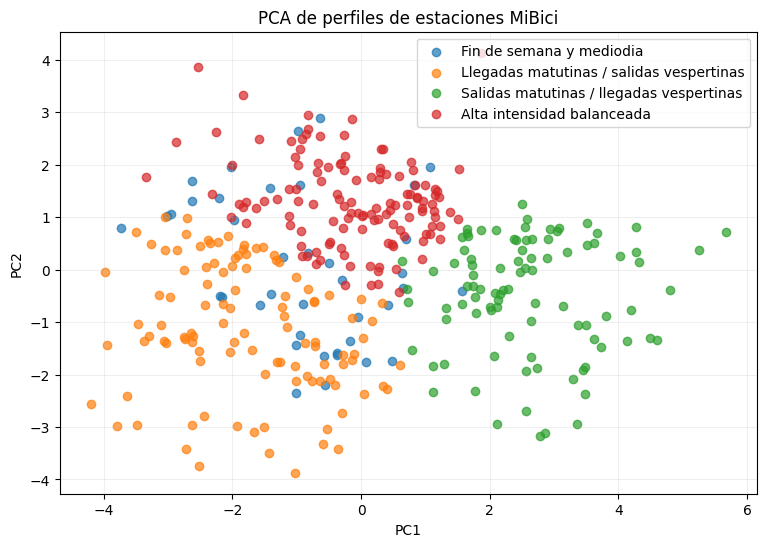

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_train_final)

pca_df = pd.DataFrame(
    X_pca,
    index=X_train_final.index,
    columns=["PC1", "PC2"]
)

pca_df["cluster"] = labels_train_final

print(
    "Varianza explicada PC1:",
    f"{pca.explained_variance_ratio_[0]:.2%}"
)

print(
    "Varianza explicada PC2:",
    f"{pca.explained_variance_ratio_[1]:.2%}"
)

print(
    "Varianza explicada acumulada:",
    f"{pca.explained_variance_ratio_.sum():.2%}"
)

plt.figure(figsize=(9, 6))

for cluster in sorted(pca_df["cluster"].unique()):
    datos = pca_df[pca_df["cluster"] == cluster]

    plt.scatter(
        datos["PC1"],
        datos["PC2"],
        label=nombres_cluster[cluster],
        alpha=0.7
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA de perfiles de estaciones MiBici")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [ ]:
loadings_pca = pd.DataFrame(
    pca.components_.T,
    index=X_train_final.columns,
    columns=["PC1", "PC2"]
)

loadings_pca["abs_PC1"] = loadings_pca["PC1"].abs()
loadings_pca["abs_PC2"] = loadings_pca["PC2"].abs()

print("Variables con mayor peso en PC1:")
display(
    loadings_pca
    .sort_values("abs_PC1", ascending=False)
    [["PC1"]]
    .head(6)
)

print("\nVariables con mayor peso en PC2:")
display(
    loadings_pca
    .sort_values("abs_PC2", ascending=False)
    [["PC2"]]
    .head(6)
)


Variables con mayor peso en PC1:


,PC1
salida_manana_share,0.451289
llegada_manana_share,-0.414876
llegada_tarde_share,0.409667
salida_tarde_share,-0.368919
llegada_noche_share,0.368636
salidas_dia,-0.214364



Variables con mayor peso en PC2:


,PC2
llegadas_dia,0.567820
salidas_dia,0.498742
balance_relativo,0.388784
salida_mediodia_share,0.290332
llegada_mediodia_share,0.267845
salida_tarde_share,-0.249607


In [ ]:
from sklearn.mixture import GaussianMixture

resultados_gmm = []

for k in range(2, 7):
    modelo = GaussianMixture(
        n_components=k,
        covariance_type="full",
        random_state=42,
        n_init=10
    )

    labels = modelo.fit_predict(X_full)
    conteos = pd.Series(labels).value_counts()

    resultados_gmm.append({
        "k": k,
        "silhouette": silhouette_score(X_full, labels),
        "davies_bouldin": davies_bouldin_score(X_full, labels),
        "calinski_harabasz": calinski_harabasz_score(X_full, labels),
        "BIC": modelo.bic(X_full),
        "AIC": modelo.aic(X_full),
        "cluster_min": conteos.min(),
        "cluster_max": conteos.max()
    })

resultados_gmm = pd.DataFrame(resultados_gmm)

display(
    resultados_gmm.style.format({
        "silhouette": "{:.4f}",
        "davies_bouldin": "{:.4f}",
        "calinski_harabasz": "{:.2f}",
        "BIC": "{:.2f}",
        "AIC": "{:.2f}"
    })
)

,k,silhouette,davies_bouldin,calinski_harabasz,BIC,AIC,cluster_min,cluster_max
0,2,0.1689,2.1003,73.13,-1372.09,-2078.96,158,209
1,3,0.1389,2.0188,52.70,-1780.93,-2843.19,77,205
2,4,0.1266,2.2180,46.29,-1483.32,-2900.97,35,179
3,5,0.1020,2.0740,46.78,-1170.48,-2943.51,31,156
4,6,0.1293,2.0386,38.51,-916.53,-3044.95,6,180


In [ ]:
resultados_gmm_estabilidad = []

for k in [2, 3, 4]:
    gmm_full = GaussianMixture(
        n_components=k,
        covariance_type="full",
        random_state=42,
        n_init=10
    )

    gmm_reducido = GaussianMixture(
        n_components=k,
        covariance_type="full",
        random_state=42,
        n_init=10
    )

    labels_full_gmm = pd.Series(
        gmm_full.fit_predict(X_full),
        index=X_full.index
    )

    labels_reducido_gmm = pd.Series(
        gmm_reducido.fit_predict(X_reducido),
        index=X_reducido.index
    )

    comunes_gmm = X_full.index.intersection(X_reducido.index)

    resultados_gmm_estabilidad.append({
        "k": k,
        "silhouette_full": silhouette_score(
            X_full,
            labels_full_gmm
        ),
        "silhouette_reducido": silhouette_score(
            X_reducido,
            labels_reducido_gmm
        ),
        "ARI": adjusted_rand_score(
            labels_full_gmm.loc[comunes_gmm],
            labels_reducido_gmm.loc[comunes_gmm]
        ),
        "NMI": normalized_mutual_info_score(
            labels_full_gmm.loc[comunes_gmm],
            labels_reducido_gmm.loc[comunes_gmm]
        ),
        "cluster_min_full": labels_full_gmm.value_counts().min(),
        "cluster_min_reducido": labels_reducido_gmm.value_counts().min()
    })

resultados_gmm_estabilidad = pd.DataFrame(
    resultados_gmm_estabilidad
)

display(
    resultados_gmm_estabilidad.style.format({
        "silhouette_full": "{:.4f}",
        "silhouette_reducido": "{:.4f}",
        "ARI": "{:.4f}",
        "NMI": "{:.4f}"
    })
)

,k,silhouette_full,silhouette_reducido,ARI,NMI,cluster_min_full,cluster_min_reducido
0,2,0.1689,0.1546,0.1237,0.0843,158,128
1,3,0.1389,0.1349,0.8229,0.7355,77,72
2,4,0.1266,0.1180,0.8746,0.8148,35,35


In [ ]:
def entropia_normalizada(serie):
    p = serie.value_counts(normalize=True)

    if len(p) <= 1:
        return 0.0

    h = -(p * np.log(p)).sum()

    return h / np.log(len(p))


def agregar_entropias(features, df):
    resultado = features.copy()
    ids = set(resultado.index)

    ent_destinos = (
        df.loc[df["Origen_Id"].isin(ids)]
        .groupby("Origen_Id")["Destino_Id"]
        .apply(entropia_normalizada)
    )

    ent_origenes = (
        df.loc[df["Destino_Id"].isin(ids)]
        .groupby("Destino_Id")["Origen_Id"]
        .apply(entropia_normalizada)
    )

    resultado["entropia_destinos"] = (
        resultado.index.to_series()
        .map(ent_destinos)
        .fillna(0)
    )

    resultado["entropia_origenes"] = (
        resultado.index.to_series()
        .map(ent_origenes)
        .fillna(0)
    )

    return resultado


features_full_v2 = agregar_entropias(
    features_full,
    train_df
)

features_reducido_v2 = agregar_entropias(
    features_reducido,
    train_reducido
)

print("Features V1:", features_full.shape[1])
print("Features V2:", features_full_v2.shape[1])

display(
    features_full_v2[
        ["entropia_destinos", "entropia_origenes"]
    ].describe()
)

print("\nSkew:")
print(
    features_full_v2[
        ["entropia_destinos", "entropia_origenes"]
    ].skew()
)

print(
    "\nFuera de [0, 1]:",
    (
        (features_full_v2[
            ["entropia_destinos", "entropia_origenes"]
        ] < 0)
        |
        (features_full_v2[
            ["entropia_destinos", "entropia_origenes"]
        ] > 1)
    ).sum().sum()
)

Features V1: 12
Features V2: 14


,entropia_destinos,entropia_origenes
count,367.000000,367.000000
mean,0.802634,0.804650
std,0.059032,0.059125
min,0.559646,0.532580
25%,0.775953,0.786701
50%,0.820116,0.820474
75%,0.844739,0.842661
max,0.877791,0.891658



Skew:
entropia_destinos   -1.433331
entropia_origenes   -1.690815
dtype: float64

Fuera de [0, 1]: 0


In [ ]:
def preparar_features_v2(features):
    X = features.copy()

    X["salidas_dia"] = np.log1p(X["salidas_dia"])
    X["llegadas_dia"] = np.log1p(X["llegadas_dia"])

    scaler = StandardScaler()

    return pd.DataFrame(
        scaler.fit_transform(X),
        index=X.index,
        columns=X.columns
    )


X_full_v2 = preparar_features_v2(features_full_v2)
X_reducido_v2 = preparar_features_v2(features_reducido_v2)

resultados_v1_v2 = []

for version, Xf, Xr in [
    ("V1_12_features", X_full, X_reducido),
    ("V2_14_features", X_full_v2, X_reducido_v2)
]:
    modelo_full = KMeans(
        n_clusters=4,
        random_state=42,
        n_init=20
    )

    modelo_reducido = KMeans(
        n_clusters=4,
        random_state=42,
        n_init=20
    )

    labels_f = pd.Series(
        modelo_full.fit_predict(Xf),
        index=Xf.index
    )

    labels_r = pd.Series(
        modelo_reducido.fit_predict(Xr),
        index=Xr.index
    )

    comunes = Xf.index.intersection(Xr.index)

    resultados_v1_v2.append({
        "version": version,
        "silhouette_full": silhouette_score(Xf, labels_f),
        "davies_bouldin_full": davies_bouldin_score(Xf, labels_f),
        "calinski_full": calinski_harabasz_score(Xf, labels_f),
        "silhouette_reducido": silhouette_score(Xr, labels_r),
        "ARI_historico": adjusted_rand_score(
            labels_f.loc[comunes],
            labels_r.loc[comunes]
        ),
        "NMI_historico": normalized_mutual_info_score(
            labels_f.loc[comunes],
            labels_r.loc[comunes]
        ),
        "cluster_min": labels_f.value_counts().min(),
        "cluster_max": labels_f.value_counts().max()
    })

resultados_v1_v2 = pd.DataFrame(resultados_v1_v2)

display(
    resultados_v1_v2.style.format({
        "silhouette_full": "{:.4f}",
        "davies_bouldin_full": "{:.4f}",
        "calinski_full": "{:.2f}",
        "silhouette_reducido": "{:.4f}",
        "ARI_historico": "{:.4f}",
        "NMI_historico": "{:.4f}"
    })
)

,version,silhouette_full,davies_bouldin_full,calinski_full,silhouette_reducido,ARI_historico,NMI_historico,cluster_min,cluster_max
0,V1_12_features,0.1864,1.5841,80.72,0.1816,0.9415,0.9167,39,127
1,V2_14_features,0.1796,1.6298,74.54,0.1740,0.9409,0.9195,39,121


In [ ]:
modelo_v1 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
)

modelo_v2 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
)

labels_v1 = pd.Series(
    modelo_v1.fit_predict(X_full),
    index=X_full.index
)

labels_v2 = pd.Series(
    modelo_v2.fit_predict(X_full_v2),
    index=X_full_v2.index
)

print(
    "ARI V1 vs V2:",
    round(adjusted_rand_score(labels_v1, labels_v2), 4)
)

print(
    "NMI V1 vs V2:",
    round(normalized_mutual_info_score(labels_v1, labels_v2), 4)
)

perfiles_v2 = features_full_v2.copy()
perfiles_v2["cluster"] = labels_v2

display(
    perfiles_v2
    .groupby("cluster")[
        ["entropia_destinos", "entropia_origenes"]
    ]
    .agg(["mean", "std", "min", "max"])
    .round(3)
)

print("\nTamaños V2:")
print(labels_v2.value_counts().sort_index())

ARI V1 vs V2: 0.8574
NMI V1 vs V2: 0.829


entropia_destinos                      entropia_origenes         \
                     mean    std    min    max              mean    std   
cluster                                                                   
0                   0.833  0.030  0.724  0.878             0.833  0.030   
1                   0.746  0.060  0.560  0.837             0.759  0.068   
2                   0.815  0.041  0.657  0.867             0.812  0.048   
3                   0.818  0.050  0.642  0.876             0.813  0.054   

                       
           min    max  
cluster                
0        0.708  0.892  
1        0.533  0.865  
2        0.641  0.869  
3        0.587  0.888


Tamaños V2:
0    121
1    102
2     39
3    105
Name: count, dtype: int64


In [ ]:
print("Correspondencia V1 vs V2:")

display(
    pd.crosstab(
        labels_v1,
        labels_v2,
        rownames=["Cluster V1"],
        colnames=["Cluster V2"]
    )
)

perfiles_v2_resumen = features_full_v2.copy()
perfiles_v2_resumen["cluster"] = labels_v2

display(
    perfiles_v2_resumen
    .groupby("cluster")
    .mean()
    .round(3)
)


Correspondencia V1 vs V2:


Cluster V2,0,1,2,3
Cluster V1,,,,
0,0,1,38,0
1,2,3,0,103
2,2,90,1,0
3,117,8,0,2


,salidas_dia,llegadas_dia,balance_relativo,share_fin_semana,salida_manana_share,llegada_manana_share,salida_mediodia_share,llegada_mediodia_share,salida_tarde_share,llegada_tarde_share,salida_noche_share,llegada_noche_share,entropia_destinos,entropia_origenes
cluster,,,,,,,,,,,,,,
0,58.185,61.161,0.026,0.202,0.293,0.247,0.296,0.295,0.333,0.363,0.078,0.095,0.833,0.833
1,13.831,15.058,0.019,0.211,0.392,0.187,0.254,0.258,0.289,0.426,0.064,0.130,0.746,0.759
2,20.336,17.345,-0.085,0.291,0.261,0.285,0.340,0.365,0.330,0.281,0.068,0.068,0.815,0.812
3,27.933,24.451,-0.094,0.180,0.218,0.372,0.272,0.264,0.424,0.295,0.086,0.069,0.818,0.813


In [ ]:
features_test_v2 = agregar_entropias(
    features_test,
    test_df
)

X_train_v2_final = features_full_v2.copy()
X_test_v2_final = features_test_v2.copy()

for df in [X_train_v2_final, X_test_v2_final]:
    df["salidas_dia"] = np.log1p(df["salidas_dia"])
    df["llegadas_dia"] = np.log1p(df["llegadas_dia"])

scaler_v2_final = StandardScaler()

X_train_v2_final = pd.DataFrame(
    scaler_v2_final.fit_transform(X_train_v2_final),
    index=X_train_v2_final.index,
    columns=X_train_v2_final.columns
)

X_test_v2_final = pd.DataFrame(
    scaler_v2_final.transform(X_test_v2_final),
    index=X_test_v2_final.index,
    columns=X_test_v2_final.columns
)

kmeans_v2_final = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
)

labels_train_v2_final = pd.Series(
    kmeans_v2_final.fit_predict(X_train_v2_final),
    index=X_train_v2_final.index
)

labels_test_v2_final = pd.Series(
    kmeans_v2_final.predict(X_test_v2_final),
    index=X_test_v2_final.index
)

comunes_v2_test = (
    X_train_v2_final.index
    .intersection(X_test_v2_final.index)
)

print("Estaciones TRAIN:", len(X_train_v2_final))
print("Estaciones TEST:", len(X_test_v2_final))
print("Estaciones comunes:", len(comunes_v2_test))

print(
    "\nSilhouette TRAIN:",
    round(
        silhouette_score(
            X_train_v2_final,
            labels_train_v2_final
        ),
        4
    )
)

print(
    "Silhouette TEST:",
    round(
        silhouette_score(
            X_test_v2_final,
            labels_test_v2_final
        ),
        4
    )
)

print(
    "Davies-Bouldin TEST:",
    round(
        davies_bouldin_score(
            X_test_v2_final,
            labels_test_v2_final
        ),
        4
    )
)

print(
    "Calinski-Harabasz TEST:",
    round(
        calinski_harabasz_score(
            X_test_v2_final,
            labels_test_v2_final
        ),
        2
    )
)

print(
    "\nARI TRAIN vs TEST:",
    round(
        adjusted_rand_score(
            labels_train_v2_final.loc[comunes_v2_test],
            labels_test_v2_final.loc[comunes_v2_test]
        ),
        4
    )
)

print(
    "NMI TRAIN vs TEST:",
    round(
        normalized_mutual_info_score(
            labels_train_v2_final.loc[comunes_v2_test],
            labels_test_v2_final.loc[comunes_v2_test]
        ),
        4
    )
)

comparacion_v2_test = pd.DataFrame({
    "train": labels_train_v2_final.loc[comunes_v2_test],
    "test": labels_test_v2_final.loc[comunes_v2_test]
})

print(
    "\nEstabilidad exacta:",
    f"{(comparacion_v2_test['train'] == comparacion_v2_test['test']).mean():.2%}"
)

Estaciones TRAIN: 367
Estaciones TEST: 367
Estaciones comunes: 366

Silhouette TRAIN: 0.1796
Silhouette TEST: 0.1586
Davies-Bouldin TEST: 1.8228
Calinski-Harabasz TEST: 65.41

ARI TRAIN vs TEST: 0.7548
NMI TRAIN vs TEST: 0.711

Estabilidad exacta: 89.62%


In [ ]:
resultado_p3 = features_full.copy()

resultado_p3["cluster"] = labels_train_final
resultado_p3["perfil"] = resultado_p3["cluster"].map(nombres_cluster)

resultado_p3["entropia_destinos"] = (
    features_full_v2["entropia_destinos"]
)

resultado_p3["entropia_origenes"] = (
    features_full_v2["entropia_origenes"]
)

resultado_p3["estabilidad_test"] = (
    resultado_p3.index.to_series()
    .map(
        comparacion_test["cambio"]
        .map({False: True, True: False})
    )
)

print("Estaciones:", len(resultado_p3))
print("Columnas:", resultado_p3.shape[1])

display(resultado_p3.head())

Estaciones: 367
Columnas: 17


,salidas_dia,llegadas_dia,balance_relativo,share_fin_semana,salida_manana_share,llegada_manana_share,salida_mediodia_share,llegada_mediodia_share,salida_tarde_share,llegada_tarde_share,salida_noche_share,llegada_noche_share,cluster,perfil,entropia_destinos,entropia_origenes,estabilidad_test
estacion,,,,,,,,,,,,,,,,,
2,50.643836,54.123288,0.033211,0.180701,0.353327,0.267654,0.270895,0.266135,0.321680,0.412744,0.054098,0.053467,3,Alta intensidad balanceada,0.828362,0.826224,True
3,50.633562,45.178082,-0.056940,0.192194,0.258032,0.339069,0.261346,0.260992,0.384579,0.312841,0.096043,0.087098,1,Llegadas matutinas / salidas vespertinas,0.817714,0.805074,True
4,63.767123,61.917808,-0.014714,0.223324,0.212567,0.342533,0.253061,0.280918,0.419066,0.303097,0.115306,0.073451,1,Llegadas matutinas / salidas vespertinas,0.806740,0.836949,True
5,51.092466,52.613014,0.014662,0.185457,0.415376,0.293953,0.297473,0.274100,0.243917,0.339908,0.043233,0.092039,3,Alta intensidad balanceada,0.805132,0.773888,True
6,24.424658,32.184932,0.137084,0.214217,0.364414,0.233028,0.281268,0.288359,0.274257,0.375293,0.080062,0.103320,3,Alta intensidad balanceada,0.794635,0.833930,True


In [ ]:
NOMENCLATURA_PATH = Path(
    "/content/drive/Othercomputers/Mi portátil/Documents/MNA/Operaciones de aprendizaje automático/datamibici2025/nomenclatura_2026_09.csv"
)

encoding_nom = detectar_encoding(NOMENCLATURA_PATH)

nomenclatura = pd.read_csv(
    NOMENCLATURA_PATH,
    encoding=encoding_nom
)

print("Encoding:", encoding_nom)
print("Shape:", nomenclatura.shape)

print("\nColumnas:")
print(nomenclatura.columns.tolist())

print("\nIDs duplicados:")
print(nomenclatura["id"].duplicated().sum())

print("\nNulos:")
print(
    nomenclatura[
        ["id", "name", "latitude", "longitude"]
    ].isna().sum()
)

ids_modelo = set(resultado_p3.index)
ids_nomenclatura = set(nomenclatura["id"])

print("\nEstaciones del modelo:", len(ids_modelo))
print("Encontradas en nomenclatura:", len(ids_modelo & ids_nomenclatura))
print("Faltantes:", sorted(ids_modelo - ids_nomenclatura))

Encoding: utf-8-sig
Shape: (484, 5)

Columnas:
['id', 'name', 'latitude', 'longitude', 'dpcapacity']

IDs duplicados:
0

Nulos:
id           0
name         0
latitude     0
longitude    0
dtype: int64

Estaciones del modelo: 367
Encontradas en nomenclatura: 367
Faltantes: []


In [ ]:
resultado_geo = (
    resultado_p3
    .reset_index()
    .merge(
        nomenclatura[
            ["id", "name", "latitude", "longitude"]
        ],
        left_on="estacion",
        right_on="id",
        how="left",
        validate="one_to_one"
    )
    .drop(columns="id")
)

print("Estaciones:", len(resultado_geo))
print("Coordenadas nulas:", resultado_geo[["latitude", "longitude"]].isna().sum().sum())

print("\nRango latitud:")
print(resultado_geo["latitude"].min(), resultado_geo["latitude"].max())

print("\nRango longitud:")
print(resultado_geo["longitude"].min(), resultado_geo["longitude"].max())

print("\nEstaciones por perfil:")
print(resultado_geo["perfil"].value_counts())

display(
    resultado_geo[
        [
            "estacion",
            "name",
            "latitude",
            "longitude",
            "cluster",
            "perfil",
            "salidas_dia",
            "llegadas_dia",
            "entropia_destinos",
            "entropia_origenes",
            "estabilidad_test"
        ]
    ].head()
)

Estaciones: 367
Coordenadas nulas: 0

Rango latitud:
20.63613 20.73837

Rango longitud:
-103.42476374847946 -103.301239

Estaciones por perfil:
perfil
Alta intensidad balanceada                  127
Llegadas matutinas / salidas vespertinas    108
Salidas matutinas / llegadas vespertinas     93
Fin de semana y mediodia                     39
Name: count, dtype: int64


,estacion,name,latitude,longitude,cluster,perfil,salidas_dia,llegadas_dia,entropia_destinos,entropia_origenes,estabilidad_test
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.666378,-103.348820,3,Alta intensidad balanceada,50.643836,54.123288,0.828362,0.826224,True
1,3,(GDL-002) C. Colonias / Av. Niños héroes,20.667228,-103.366000,1,Llegadas matutinas / salidas vespertinas,50.633562,45.178082,0.817714,0.805074,True
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,20.667690,-103.368252,1,Llegadas matutinas / salidas vespertinas,63.767123,61.917808,0.806740,0.836949,True
3,5,(GDL-004) C. Ghilardi /C. Miraflores,20.691847,-103.362549,3,Alta intensidad balanceada,51.092466,52.613014,0.805132,0.773888,True
4,6,(GDL-005) C. San Diego /Calzada Independencia,20.681158,-103.339363,3,Alta intensidad balanceada,24.424658,32.184932,0.794635,0.833930,True


In [ ]:
import folium
from folium.plugins import Fullscreen
from branca.element import Element
from IPython.display import display

colores_cluster = {
    0: "#e74c3c",
    1: "#3498db",
    2: "#2ecc71",
    3: "#8e44ad"
}

mapa_p3 = folium.Map(
    location=[
        resultado_geo["latitude"].mean(),
        resultado_geo["longitude"].mean()
    ],
    tiles=None,
    zoom_start=13,
    control_scale=True,
    prefer_canvas=True
)

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri",
    name="Esri WorldStreetMap",
    overlay=False,
    control=False
).add_to(mapa_p3)

Fullscreen(
    position="topleft",
    title="Pantalla completa",
    title_cancel="Salir"
).add_to(mapa_p3)

capas = {}

for cluster, perfil in nombres_cluster.items():
    n = (resultado_geo["cluster"] == cluster).sum()

    capas[cluster] = folium.FeatureGroup(
        name=f"{cluster} - {perfil} ({n})",
        show=True
    )

    capas[cluster].add_to(mapa_p3)

for _, fila in resultado_geo.iterrows():
    popup = f"""
    <div style="width:310px">
        <b>{fila['name']}</b><br><br>
        <b>Estación:</b> {int(fila['estacion'])}<br>
        <b>Perfil:</b> {fila['perfil']}<br>
        <b>Cluster:</b> {int(fila['cluster'])}<br><br>

        <b>Salidas/día:</b> {fila['salidas_dia']:.1f}<br>
        <b>Llegadas/día:</b> {fila['llegadas_dia']:.1f}<br>
        <b>Balance:</b> {fila['balance_relativo']:.3f}<br>
        <b>Fin de semana:</b> {fila['share_fin_semana']:.1%}<br><br>

        <b>Entropía destinos:</b> {fila['entropia_destinos']:.3f}<br>
        <b>Entropía orígenes:</b> {fila['entropia_origenes']:.3f}<br>
        <b>Estable en TEST:</b> {"Sí" if fila['estabilidad_test'] else "No"}
    </div>
    """

    folium.CircleMarker(
        location=[
            fila["latitude"],
            fila["longitude"]
        ],
        radius=5,
        color=colores_cluster[fila["cluster"]],
        weight=1.5,
        fill=True,
        fill_color=colores_cluster[fila["cluster"]],
        fill_opacity=0.80,
        popup=folium.Popup(popup, max_width=350),
        tooltip=f"{fila['name']} | {fila['perfil']}"
    ).add_to(capas[fila["cluster"]])

folium.LayerControl(
    collapsed=False,
    position="topright"
).add_to(mapa_p3)

mapa_p3.fit_bounds([
    [
        resultado_geo["latitude"].min(),
        resultado_geo["longitude"].min()
    ],
    [
        resultado_geo["latitude"].max(),
        resultado_geo["longitude"].max()
    ]
])

leyenda = """
<div style="
    position: fixed;
    bottom: 30px;
    left: 30px;
    z-index: 9999;
    background-color: white;
    padding: 12px 16px;
    border: 1px solid #999;
    border-radius: 6px;
    font-size: 13px;
    box-shadow: 0 1px 5px rgba(0,0,0,0.3);
">
<b>Perfiles de estaciones MiBici</b><br><br>
<span style="color:#e74c3c;">●</span> Fin de semana y mediodía<br>
<span style="color:#3498db;">●</span> Llegadas matutinas / salidas vespertinas<br>
<span style="color:#2ecc71;">●</span> Salidas matutinas / llegadas vespertinas<br>
<span style="color:#8e44ad;">●</span> Alta intensidad balanceada
</div>
"""

mapa_p3.get_root().html.add_child(Element(leyenda))

MAPA_FINAL_PATH = "/content/mapa_p3_mibici_final.html"
mapa_p3.save(MAPA_FINAL_PATH)

print("Mapa final guardado en:", MAPA_FINAL_PATH)

display(mapa_p3)

Mapa final guardado en: /content/mapa_p3_mibici_final.html


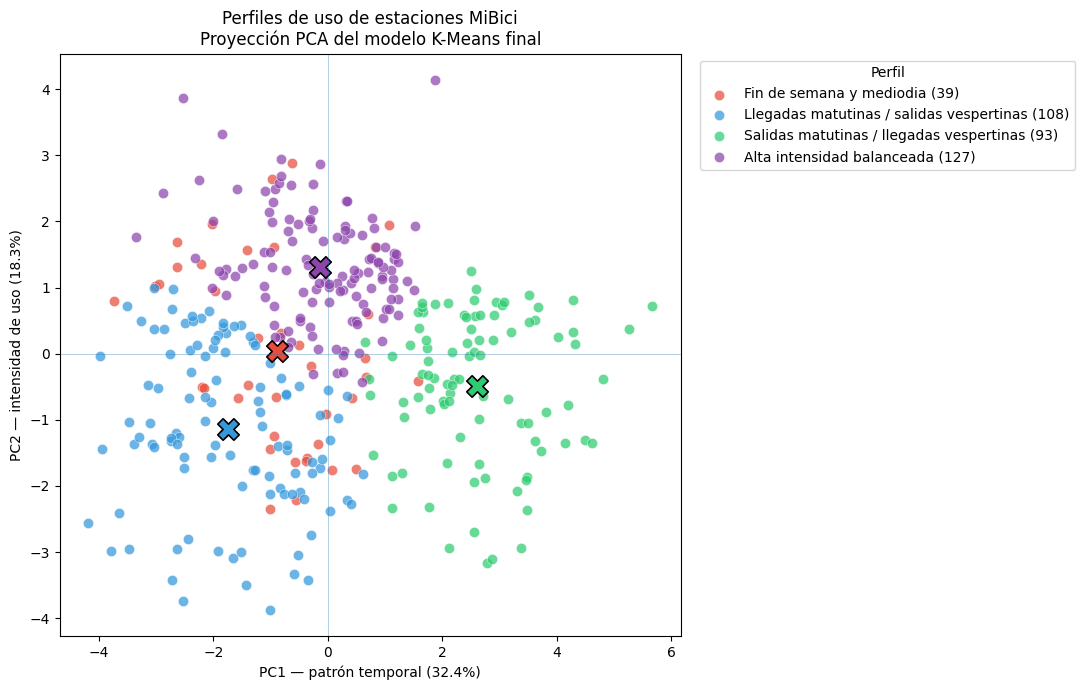

PCA guardado en: /content/pca_p3_mibici_final.png
Varianza explicada acumulada: 50.69%


In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca_final = PCA(n_components=2)

X_pca_final = pca_final.fit_transform(X_train_final)

pca_final_df = pd.DataFrame(
    X_pca_final,
    index=X_train_final.index,
    columns=["PC1", "PC2"]
)

pca_final_df["cluster"] = labels_train_final

colores_pca = {
    0: "#e74c3c",
    1: "#3498db",
    2: "#2ecc71",
    3: "#8e44ad"
}

plt.figure(figsize=(11, 7))

for cluster in sorted(pca_final_df["cluster"].unique()):
    datos = pca_final_df[
        pca_final_df["cluster"] == cluster
    ]

    plt.scatter(
        datos["PC1"],
        datos["PC2"],
        s=55,
        alpha=0.72,
        label=f"{nombres_cluster[cluster]} ({len(datos)})",
        color=colores_pca[cluster],
        edgecolors="white",
        linewidths=0.4
    )

centroides_pca = (
    pca_final_df
    .groupby("cluster")[["PC1", "PC2"]]
    .mean()
)

for cluster, fila in centroides_pca.iterrows():
    plt.scatter(
        fila["PC1"],
        fila["PC2"],
        s=240,
        marker="X",
        color=colores_pca[cluster],
        edgecolors="black",
        linewidths=1.2
    )

plt.axhline(0, linewidth=0.6, alpha=0.4)
plt.axvline(0, linewidth=0.6, alpha=0.4)

plt.xlabel(
    f"PC1 — patrón temporal ({pca_final.explained_variance_ratio_[0]:.1%})"
)

plt.ylabel(
    f"PC2 — intensidad de uso ({pca_final.explained_variance_ratio_[1]:.1%})"
)

plt.title(
    "Perfiles de uso de estaciones MiBici\n"
    "Proyección PCA del modelo K-Means final"
)

plt.legend(
    title="Perfil",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

PCA_FINAL_PATH = "/content/pca_p3_mibici_final.png"

plt.savefig(
    PCA_FINAL_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("PCA guardado en:", PCA_FINAL_PATH)
print(
    "Varianza explicada acumulada:",
    f"{pca_final.explained_variance_ratio_.sum():.2%}"
)

In [ ]:
tabla_maestra = (
    resultado_p3
    .reset_index()
    .groupby(["cluster", "perfil"], as_index=False)
    .agg(
        estaciones=("estacion", "size"),
        salidas_dia=("salidas_dia", "mean"),
        llegadas_dia=("llegadas_dia", "mean"),
        balance_relativo=("balance_relativo", "mean"),
        share_fin_semana=("share_fin_semana", "mean"),
        entropia_destinos=("entropia_destinos", "mean"),
        entropia_origenes=("entropia_origenes", "mean"),
        estabilidad_test=("estabilidad_test", "mean")
    )
    .sort_values("cluster")
)

tabla_maestra["estabilidad_test"] = (
    tabla_maestra["estabilidad_test"] * 100
)

tabla_maestra = tabla_maestra.round({
    "salidas_dia": 2,
    "llegadas_dia": 2,
    "balance_relativo": 3,
    "share_fin_semana": 3,
    "entropia_destinos": 3,
    "entropia_origenes": 3,
    "estabilidad_test": 2
})

display(tabla_maestra)

,cluster,perfil,estaciones,salidas_dia,llegadas_dia,balance_relativo,share_fin_semana,entropia_destinos,entropia_origenes,estabilidad_test
0,0,Fin de semana y mediodia,39,20.40,17.35,-0.088,0.291,0.813,0.810,89.74359
1,1,Llegadas matutinas / salidas vespertinas,108,27.44,24.05,-0.092,0.181,0.818,0.812,83.333333
2,2,Salidas matutinas / llegadas vespertinas,93,13.03,14.44,0.022,0.212,0.755,0.770,91.397849
3,3,Alta intensidad balanceada,127,56.75,59.55,0.026,0.202,0.822,0.822,97.619048


In [ ]:
perfiles_cluster = (
    features_full
    .assign(cluster=labels_train_final)
    .groupby("cluster")
    .mean()
)

clusters_disponibles = set(perfiles_cluster.index)

cluster_alta = (
    perfiles_cluster["salidas_dia"] +
    perfiles_cluster["llegadas_dia"]
).idxmax()

clusters_disponibles.remove(cluster_alta)

cluster_fin_semana = (
    perfiles_cluster.loc[list(clusters_disponibles), "share_fin_semana"]
    .idxmax()
)

clusters_disponibles.remove(cluster_fin_semana)

score_residencial = (
    perfiles_cluster.loc[list(clusters_disponibles), "salida_manana_share"] +
    perfiles_cluster.loc[list(clusters_disponibles), "llegada_tarde_share"]
)

cluster_salidas_manana = score_residencial.idxmax()

clusters_disponibles.remove(cluster_salidas_manana)

cluster_llegadas_manana = clusters_disponibles.pop()

nombres_cluster_auto = {
    cluster_alta: "Alta intensidad balanceada",
    cluster_fin_semana: "Fin de semana y mediodia",
    cluster_salidas_manana: "Salidas matutinas / llegadas vespertinas",
    cluster_llegadas_manana: "Llegadas matutinas / salidas vespertinas"
}

print(nombres_cluster_auto)

display(
    perfiles_cluster[
        [
            "salidas_dia",
            "llegadas_dia",
            "share_fin_semana",
            "salida_manana_share",
            "llegada_manana_share",
            "salida_tarde_share",
            "llegada_tarde_share"
        ]
    ].round(3)
)

{np.int32(3): 'Alta intensidad balanceada', np.int32(0): 'Fin de semana y mediodia', np.int32(2): 'Salidas matutinas / llegadas vespertinas', 1: 'Llegadas matutinas / salidas vespertinas'}


,salidas_dia,llegadas_dia,share_fin_semana,salida_manana_share,llegada_manana_share,salida_tarde_share,llegada_tarde_share
cluster,,,,,,,
0,20.399,17.351,0.291,0.261,0.283,0.329,0.283
1,27.437,24.053,0.181,0.217,0.369,0.424,0.297
2,13.027,14.435,0.212,0.405,0.181,0.283,0.430
3,56.748,59.554,0.202,0.294,0.247,0.333,0.364


In [ ]:
nombres_cluster_auto = {
    int(k): v for k, v in nombres_cluster_auto.items()
}

resultado_p3_auto = features_full.copy()

resultado_p3_auto["cluster"] = (
    labels_train_final.astype(int)
)

resultado_p3_auto["perfil"] = (
    resultado_p3_auto["cluster"]
    .map(nombres_cluster_auto)
)

resultado_p3_auto["entropia_destinos"] = (
    features_full_v2["entropia_destinos"]
)

resultado_p3_auto["entropia_origenes"] = (
    features_full_v2["entropia_origenes"]
)

metricas_cluster = (
    resultado_p3_auto
    .reset_index()
    .groupby(["cluster", "perfil"], as_index=False)
    .agg(
        estaciones_train=("estacion", "size"),
        salidas_dia=("salidas_dia", "mean"),
        llegadas_dia=("llegadas_dia", "mean"),
        balance_relativo=("balance_relativo", "mean"),
        share_fin_semana=("share_fin_semana", "mean"),
        entropia_destinos=("entropia_destinos", "mean"),
        entropia_origenes=("entropia_origenes", "mean")
    )
)

estabilidad_cluster_auto = (
    comparacion_test
    .groupby("cluster_train")
    .agg(
        comparables_test=("cambio", "size"),
        cambios_test=("cambio", "sum")
    )
)

estabilidad_cluster_auto["estables_test"] = (
    estabilidad_cluster_auto["comparables_test"] -
    estabilidad_cluster_auto["cambios_test"]
)

estabilidad_cluster_auto["estabilidad_pct"] = (
    estabilidad_cluster_auto["estables_test"] /
    estabilidad_cluster_auto["comparables_test"] * 100
)

tabla_maestra_final = (
    metricas_cluster
    .merge(
        estabilidad_cluster_auto,
        left_on="cluster",
        right_index=True,
        how="left"
    )
    .sort_values("cluster")
)

tabla_maestra_final = tabla_maestra_final.round({
    "salidas_dia": 2,
    "llegadas_dia": 2,
    "balance_relativo": 3,
    "share_fin_semana": 3,
    "entropia_destinos": 3,
    "entropia_origenes": 3,
    "estabilidad_pct": 2
})

display(tabla_maestra_final)

,cluster,perfil,estaciones_train,salidas_dia,llegadas_dia,balance_relativo,share_fin_semana,entropia_destinos,entropia_origenes,comparables_test,cambios_test,estables_test,estabilidad_pct
0,0,Fin de semana y mediodia,39,20.40,17.35,-0.088,0.291,0.813,0.810,39,4,35,89.74
1,1,Llegadas matutinas / salidas vespertinas,108,27.44,24.05,-0.092,0.181,0.818,0.812,108,18,90,83.33
2,2,Salidas matutinas / llegadas vespertinas,93,13.03,14.44,0.022,0.212,0.755,0.770,93,8,85,91.40
3,3,Alta intensidad balanceada,127,56.75,59.55,0.026,0.202,0.822,0.822,126,3,123,97.62


In [ ]:
resultado_final = features_full.copy()

resultado_final["cluster"] = labels_train_final.astype(int)

resultado_final["perfil"] = (
    resultado_final["cluster"]
    .map(nombres_cluster_auto)
)

resultado_final["entropia_destinos"] = (
    features_full_v2["entropia_destinos"]
)

resultado_final["entropia_origenes"] = (
    features_full_v2["entropia_origenes"]
)

estado_test = pd.Series(
    "no_comparable",
    index=resultado_final.index,
    dtype="object"
)

estado_test.loc[comparacion_test.index] = np.where(
    comparacion_test["cambio"],
    "cambio",
    "estable"
)

resultado_final["estado_test"] = estado_test

resultado_geo_final = (
    resultado_final
    .reset_index()
    .merge(
        nomenclatura[
            ["id", "name", "latitude", "longitude"]
        ],
        left_on="estacion",
        right_on="id",
        how="left",
        validate="one_to_one"
    )
    .drop(columns="id")
)

print("Estaciones finales:", len(resultado_final))

print("\nEstado frente a TEST:")
print(resultado_final["estado_test"].value_counts())

print("\nPerfiles:")
print(resultado_final["perfil"].value_counts())

print("\nNo comparables:")
display(
    resultado_geo_final.loc[
        resultado_geo_final["estado_test"] == "no_comparable",
        [
            "estacion",
            "name",
            "cluster",
            "perfil",
            "estado_test"
        ]
    ]
)

Estaciones finales: 367

Estado frente a TEST:
estado_test
estable          333
cambio            33
no_comparable      1
Name: count, dtype: int64

Perfiles:
perfil
Alta intensidad balanceada                  127
Llegadas matutinas / salidas vespertinas    108
Salidas matutinas / llegadas vespertinas     93
Fin de semana y mediodia                     39
Name: count, dtype: int64

No comparables:


,estacion,name,cluster,perfil,estado_test
17,20,(GDL-018) Av. México / C. Manuel M. Diéguez,3,Alta intensidad balanceada,no_comparable


In [ ]:
import folium
from folium.plugins import Fullscreen
from branca.element import Element
from IPython.display import display

colores_perfil = {
    "Fin de semana y mediodia": "#e74c3c",
    "Llegadas matutinas / salidas vespertinas": "#3498db",
    "Salidas matutinas / llegadas vespertinas": "#2ecc71",
    "Alta intensidad balanceada": "#8e44ad"
}

mapa_final = folium.Map(
    location=[
        resultado_geo_final["latitude"].mean(),
        resultado_geo_final["longitude"].mean()
    ],
    tiles=None,
    zoom_start=13,
    control_scale=True,
    prefer_canvas=True
)

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri",
    name="Esri WorldStreetMap",
    overlay=False,
    control=False
).add_to(mapa_final)

Fullscreen(
    position="topleft",
    title="Pantalla completa",
    title_cancel="Salir"
).add_to(mapa_final)

capas = {}

for perfil in colores_perfil:
    n = (resultado_geo_final["perfil"] == perfil).sum()

    capas[perfil] = folium.FeatureGroup(
        name=f"{perfil} ({n})",
        show=True
    )

    capas[perfil].add_to(mapa_final)

for _, fila in resultado_geo_final.iterrows():
    color = colores_perfil[fila["perfil"]]

    estado = {
        "estable": "Estable",
        "cambio": "Cambió de perfil",
        "no_comparable": "No comparable"
    }[fila["estado_test"]]

    popup = f"""
    <div style="width:320px">
        <b>{fila['name']}</b><br><br>
        <b>Estación:</b> {int(fila['estacion'])}<br>
        <b>Perfil:</b> {fila['perfil']}<br>
        <b>Cluster:</b> {int(fila['cluster'])}<br>
        <b>Estado en TEST:</b> {estado}<br><br>

        <b>Salidas/día:</b> {fila['salidas_dia']:.1f}<br>
        <b>Llegadas/día:</b> {fila['llegadas_dia']:.1f}<br>
        <b>Balance:</b> {fila['balance_relativo']:.3f}<br>
        <b>Fin de semana:</b> {fila['share_fin_semana']:.1%}<br><br>

        <b>Entropía destinos:</b> {fila['entropia_destinos']:.3f}<br>
        <b>Entropía orígenes:</b> {fila['entropia_origenes']:.3f}
    </div>
    """

    folium.CircleMarker(
        location=[fila["latitude"], fila["longitude"]],
        radius=5,
        color=color,
        weight=1.5,
        fill=True,
        fill_color=color,
        fill_opacity=0.80,
        popup=folium.Popup(popup, max_width=350),
        tooltip=f"{fila['name']} | {fila['perfil']} | {estado}"
    ).add_to(capas[fila["perfil"]])

folium.LayerControl(
    collapsed=False,
    position="topright"
).add_to(mapa_final)

mapa_final.fit_bounds([
    [
        resultado_geo_final["latitude"].min(),
        resultado_geo_final["longitude"].min()
    ],
    [
        resultado_geo_final["latitude"].max(),
        resultado_geo_final["longitude"].max()
    ]
])

leyenda = """
<div style="
    position: fixed;
    bottom: 30px;
    left: 30px;
    z-index: 9999;
    background-color: white;
    padding: 12px 16px;
    border: 1px solid #999;
    border-radius: 6px;
    font-size: 13px;
    box-shadow: 0 1px 5px rgba(0,0,0,0.3);
">
<b>Perfiles de estaciones MiBici</b><br><br>
<span style="color:#e74c3c;">●</span> Fin de semana y mediodía<br>
<span style="color:#3498db;">●</span> Llegadas matutinas / salidas vespertinas<br>
<span style="color:#2ecc71;">●</span> Salidas matutinas / llegadas vespertinas<br>
<span style="color:#8e44ad;">●</span> Alta intensidad balanceada
</div>
"""

mapa_final.get_root().html.add_child(Element(leyenda))

MAPA_FINAL_PATH = "/content/mapa_p3_mibici_final.html"
mapa_final.save(MAPA_FINAL_PATH)

print("Mapa final:", MAPA_FINAL_PATH)
print("Estaciones:", len(resultado_geo_final))
print(resultado_geo_final["estado_test"].value_counts())

display(mapa_final)

Mapa final: /content/mapa_p3_mibici_final.html
Estaciones: 367
estado_test
estable          333
cambio            33
no_comparable      1
Name: count, dtype: int64


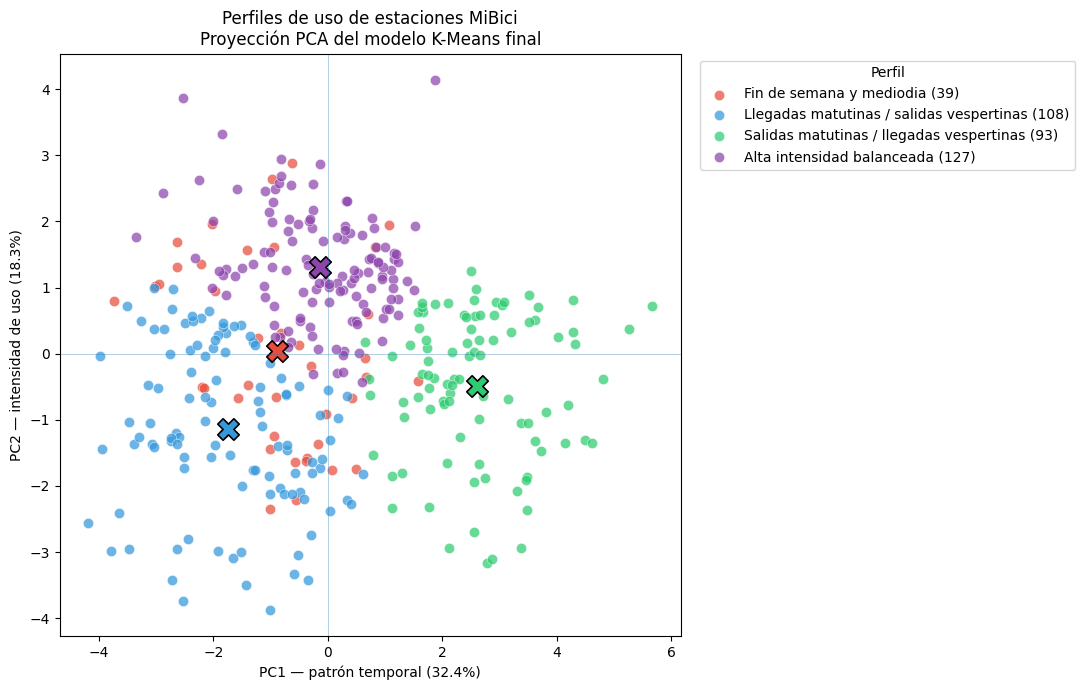

PCA final: /content/pca_p3_mibici_final.png
Varianza explicada acumulada: 50.69%


In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca_final = PCA(n_components=2)

X_pca_final = pca_final.fit_transform(X_train_final)

pca_final_df = pd.DataFrame(
    X_pca_final,
    index=X_train_final.index,
    columns=["PC1", "PC2"]
)

pca_final_df["cluster"] = labels_train_final.astype(int)
pca_final_df["perfil"] = pca_final_df["cluster"].map(nombres_cluster_auto)

colores_perfil = {
    "Fin de semana y mediodia": "#e74c3c",
    "Llegadas matutinas / salidas vespertinas": "#3498db",
    "Salidas matutinas / llegadas vespertinas": "#2ecc71",
    "Alta intensidad balanceada": "#8e44ad"
}

plt.figure(figsize=(11, 7))

for perfil, color in colores_perfil.items():
    datos = pca_final_df[pca_final_df["perfil"] == perfil]

    plt.scatter(
        datos["PC1"],
        datos["PC2"],
        s=55,
        alpha=0.72,
        label=f"{perfil} ({len(datos)})",
        color=color,
        edgecolors="white",
        linewidths=0.4
    )

centroides = (
    pca_final_df
    .groupby("perfil")[["PC1", "PC2"]]
    .mean()
)

for perfil, fila in centroides.iterrows():
    plt.scatter(
        fila["PC1"],
        fila["PC2"],
        s=240,
        marker="X",
        color=colores_perfil[perfil],
        edgecolors="black",
        linewidths=1.2
    )

plt.axhline(0, linewidth=0.6, alpha=0.4)
plt.axvline(0, linewidth=0.6, alpha=0.4)

plt.xlabel(
    f"PC1 — patrón temporal ({pca_final.explained_variance_ratio_[0]:.1%})"
)

plt.ylabel(
    f"PC2 — intensidad de uso ({pca_final.explained_variance_ratio_[1]:.1%})"
)

plt.title(
    "Perfiles de uso de estaciones MiBici\n"
    "Proyección PCA del modelo K-Means final"
)

plt.legend(
    title="Perfil",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

PCA_FINAL_PATH = "/content/pca_p3_mibici_final.png"

plt.savefig(
    PCA_FINAL_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("PCA final:", PCA_FINAL_PATH)
print(
    "Varianza explicada acumulada:",
    f"{pca_final.explained_variance_ratio_.sum():.2%}"
)

In [ ]:
from pathlib import Path
import shutil

ARTIFACT_DIR = Path("/content/p3_artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

resultado_final.to_parquet(
    ARTIFACT_DIR / "resultado_p3.parquet"
)

resultado_geo_final.to_parquet(
    ARTIFACT_DIR / "resultado_p3_geo.parquet",
    index=False
)

tabla_maestra_final.to_csv(
    ARTIFACT_DIR / "tabla_maestra_clusters.csv",
    index=False
)

shutil.copy(
    PCA_FINAL_PATH,
    ARTIFACT_DIR / "pca_p3_mibici_final.png"
)

shutil.copy(
    MAPA_FINAL_PATH,
    ARTIFACT_DIR / "mapa_p3_mibici_final.html"
)

print("Artefactos guardados:")

for archivo in sorted(ARTIFACT_DIR.iterdir()):
    print(
        archivo.name,
        f"{archivo.stat().st_size / 1024:.1f} KB"
    )

Artefactos guardados:
mapa_p3_mibici_final.html 673.4 KB
pca_p3_mibici_final.png 449.7 KB
resultado_p3.parquet 58.3 KB
resultado_p3_geo.parquet 74.8 KB
tabla_maestra_clusters.csv 0.5 KB


In [ ]:
import joblib

model_bundle = {
    "scaler": scaler_final,
    "kmeans": kmeans_final,
    "features": list(features_full.columns),
    "perfiles": nombres_cluster_auto
}

MODEL_PATH = ARTIFACT_DIR / "p3_model_bundle.joblib"

joblib.dump(
    model_bundle,
    MODEL_PATH
)

print("Modelo guardado en:", MODEL_PATH)

Modelo guardado en: /content/p3_artifacts/p3_model_bundle.joblib


In [ ]:
!pip install -q mlflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 3.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 58.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 69.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 58.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 16.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 16.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
import mlflow
print(mlflow.__version__)

3.17.1


In [ ]:
import mlflow

mlflow.set_experiment("mibici-p3-clustering")

hist_k4 = resultados_estabilidad.loc[
    resultados_estabilidad["k"] == 4
].iloc[0]

with mlflow.start_run(run_name="p3_kmeans_final") as run:

    mlflow.log_params({
        "modelo": "KMeans",
        "k": 4,
        "random_state": 42,
        "n_init": 20,
        "features": 12,
        "max_inactivity_days": 60,
        "min_history_days": 30,
        "min_duration_seconds": 60,
        "max_duration_seconds": 86400,
        "split": "temporal_80_20",
        "train_inicio": "2025-01-01",
        "train_fin": "2025-10-19",
        "test_inicio": "2025-10-20",
        "test_fin": "2025-12-31",
        "transformacion_intensidad": "log1p",
        "scaler": "StandardScaler"
    })

    mlflow.log_metrics({
        "silhouette_train": silhouette_score(
            X_train_final,
            labels_train_final
        ),
        "silhouette_test": silhouette_score(
            X_test_final,
            labels_test_final
        ),
        "davies_bouldin_train": davies_bouldin_score(
            X_train_final,
            labels_train_final
        ),
        "davies_bouldin_test": davies_bouldin_score(
            X_test_final,
            labels_test_final
        ),
        "calinski_harabasz_train": calinski_harabasz_score(
            X_train_final,
            labels_train_final
        ),
        "calinski_harabasz_test": calinski_harabasz_score(
            X_test_final,
            labels_test_final
        ),
        "ari_train_test": adjusted_rand_score(
            labels_train_final.loc[comunes_test],
            labels_test_final.loc[comunes_test]
        ),
        "nmi_train_test": normalized_mutual_info_score(
            labels_train_final.loc[comunes_test],
            labels_test_final.loc[comunes_test]
        ),
        "estabilidad_exacta_test": (
            comparacion_test["cluster_train"]
            == comparacion_test["cluster_test"]
        ).mean(),
        "ari_historico_reducido": hist_k4["ARI"],
        "nmi_historico_reducido": hist_k4["NMI"],
        "estaciones_train": len(X_train_final),
        "estaciones_test": len(X_test_final),
        "estaciones_comunes": len(comunes_test),
        "pca_varianza_acumulada": pca_final.explained_variance_ratio_.sum()
    })

    mlflow.set_tags({
        "problema": "P3",
        "tipo": "clustering",
        "estado": "modelo_final",
        "pregunta": "Grupos de estaciones con patrones de uso y distribución geográfica"
    })

    for archivo in [
        "p3_model_bundle.joblib",
        "mapa_p3_mibici_final.html",
        "pca_p3_mibici_final.png",
        "resultado_p3_geo.parquet",
        "tabla_maestra_clusters.csv"
    ]:
        mlflow.log_artifact(
            ARTIFACT_DIR / archivo,
            artifact_path="p3"
        )

    print("Run ID:", run.info.run_id)
    print("Experimento:", "mibici-p3-clustering")

2026/10/16 05:21:41 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/16 05:21:41 INFO mlflow.store.db.utils: Updating database tables
2026/10/16 05:21:49 INFO mlflow.tracking.fluent: Experiment with name 'mibici-p3-clustering' does not exist. Creating a new experiment.


Run ID: 9677276745254096894730a098d0767c
Experimento: mibici-p3-clustering


In [ ]:
run_id = "9677276745254096894730a098d0767c"

run = mlflow.get_run(run_id)

print("Estado:", run.info.status)

print("\nParámetros:")
for k, v in sorted(run.data.params.items()):
    print(f"{k}: {v}")

print("\nMétricas:")
for k, v in sorted(run.data.metrics.items()):
    print(f"{k}: {v:.4f}")

print("\nArtefactos:")
for a in mlflow.artifacts.list_artifacts(run_id=run_id, artifact_path="p3"):
    print(a.path)

Estado: FINISHED

Parámetros:
features: 12
k: 4
max_duration_seconds: 86400
max_inactivity_days: 60
min_duration_seconds: 60
min_history_days: 30
modelo: KMeans
n_init: 20
random_state: 42
scaler: StandardScaler
split: temporal_80_20
test_fin: 2025-12-31
test_inicio: 2025-10-20
train_fin: 2025-10-19
train_inicio: 2025-01-01
transformacion_intensidad: log1p

Métricas:
ari_historico_reducido: 0.9415
ari_train_test: 0.7927
calinski_harabasz_test: 70.2985
calinski_harabasz_train: 80.7216
davies_bouldin_test: 1.7448
davies_bouldin_train: 1.5841
estabilidad_exacta_test: 0.9098
estaciones_comunes: 366.0000
estaciones_test: 367.0000
estaciones_train: 367.0000
nmi_historico_reducido: 0.9167
nmi_train_test: 0.7361
pca_varianza_acumulada: 0.5069
silhouette_test: 0.1666
silhouette_train: 0.1864

Artefactos:
p3/mapa_p3_mibici_final.html
p3/p3_model_bundle.joblib
p3/pca_p3_mibici_final.png
p3/resultado_p3_geo.parquet
p3/tabla_maestra_clusters.csv
